In [1]:
from collections import Counter
from pathlib import Path
import sys, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

repository = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "team_a/src/models/jiayi").is_dir())
sys.path.insert(0, str(repository))
from team_a.src.models.jiayi import train as training
folder = repository / "team_a/src/models/jiayi"
source = repository / "team_a/experiments/rishitha/ar1_linear"
print("Python", platform.python_version(), "NumPy", np.__version__, "Platform", platform.platform())
print("Seed", training.SEED, "epochs", training.EPOCHS, "batch size", training.BATCH_SIZE)
print("Adam: beta1=0.9, beta2=0.999, epsilon=1e-8; L2=0")
display(pd.DataFrame(training.CONFIGURATIONS))

Python 3.9.12 NumPy 1.22.4 Platform macOS-10.16-x86_64-i386-64bit
Seed 42 epochs 60 batch size 64
Adam: beta1=0.9, beta2=0.999, epsilon=1e-8; L2=0


,name,model_id,beta,learning_rate
0,aj1_bc,A-J1,0.0,0.030
1,aj2_bc,A-J2,0.0,0.003
2,aj1_weighted_bc,A-J1,0.5,0.030


In [2]:
manifest, battles, raw = training.audit_collection(source)
raw_train = training.load_split(source, "train", manifest, battles, raw)
raw_validation = training.load_split(source, "validation", manifest, battles, raw)
mean, scale, active = training.fit_normalization(raw_train)
train = training.normalize(raw_train, mean, scale)
validation = training.normalize(raw_validation, mean, scale)
print("Audit passed; active features", int(active.sum()))
display(pd.DataFrame({name: {"games": manifest[name]["games"], "decisions": manifest[name]["rows"]} for name in ("train", "validation", "held_out")}).T)
print("Training decision outcomes", dict(Counter(e["reward"] for e in raw_train)))

Audit passed; active features 140


,games,decisions
train,210,2161
validation,45,539
held_out,45,390


Training decision outcomes {1.0: 1834, -1.0: 327}


In [3]:
runs = []
for config in training.CONFIGURATIONS:
    parameters, result, history = training.train_one(config, train, validation, active)
    runs.append((config, parameters, result, history))

aj1_bc epoch 1 validation CE 0.737462


aj1_bc epoch 10 validation CE 0.692554


aj1_bc epoch 20 validation CE 0.699647


aj1_bc epoch 30 validation CE 0.694388


aj1_bc epoch 40 validation CE 0.69075


aj1_bc epoch 50 validation CE 0.688214


... (11 outputs left out)

aj1_weighted_bc epoch 30 validation CE 0.692852


aj1_weighted_bc epoch 40 validation CE 0.699984


aj1_weighted_bc epoch 50 validation CE 0.687109


aj1_weighted_bc epoch 60 validation CE 0.684922


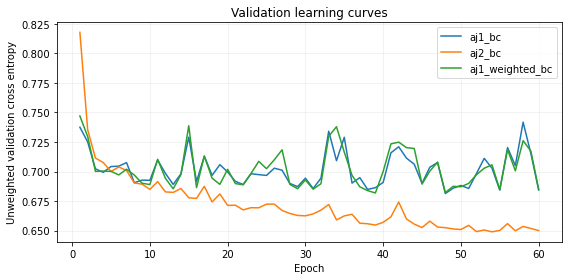

In [4]:
fig, ax = plt.subplots(figsize=(8, 4))
for config, _, _, history in runs:
    ax.plot([r["epoch"] for r in history], [r["validation_cross_entropy"] for r in history], label=config["name"])
ax.set(xlabel="Epoch", ylabel="Unweighted validation cross entropy", title="Validation learning curves")
ax.legend()
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

In [5]:
raw_test = training.load_split(source, "held_out", manifest, battles, raw)
test = training.normalize(raw_test, mean, scale)
rows = []
for config, parameters, result, history in runs:
    result["held_out"] = training.metrics(test, parameters)
    path = folder / (config["name"] + ".json")
    training.export(parameters, config, mean, scale, result, path)
    parity = training.check_reload(path, config["model_id"], parameters, raw_train[:10] + raw_validation[:10] + raw_test[:10], mean, scale)
    print(path.name, "reload/order checks", parity)
    for split in ("train", "validation", "held_out"):
        rows.append({"configuration": config["name"], "seed": training.SEED, "beta": config["beta"], "learning_rate": config["learning_rate"], "epochs": training.EPOCHS, "batch_size": training.BATCH_SIZE, "selected_epoch": result["selected_epoch"], "training_seconds": result["training_seconds"], "split": split, **result[split]})
results = pd.DataFrame(rows)
results.to_csv(folder / "results.csv", index=False)
display(results[["configuration", "split", "selected_epoch", "chosen_action_cross_entropy", "exact_choice_accuracy", "policy_entropy_nats"]])

aj1_bc.json reload/order checks {'passed': True, 'decisions_checked': 30, 'max_absolute_logit_error': 1.4210854715202004e-14, 'checks': ['logits', 'probabilities', 'reversed_candidate_order']}


aj2_bc.json reload/order checks {'passed': True, 'decisions_checked': 30, 'max_absolute_logit_error': 7.105427357601002e-15, 'checks': ['logits', 'probabilities', 'reversed_candidate_order']}
aj1_weighted_bc.json reload/order checks {'passed': True, 'decisions_checked': 30, 'max_absolute_logit_error': 1.0658141036401503e-14, 'checks': ['logits', 'probabilities', 'reversed_candidate_order']}


,configuration,split,selected_epoch,chosen_action_cross_entropy,exact_choice_accuracy,policy_entropy_nats
0,aj1_bc,train,48,0.671728,0.974549,0.667923
1,aj1_bc,validation,48,0.681347,0.977737,0.685349
2,aj1_bc,held_out,48,0.678851,0.971795,0.636552
3,aj2_bc,train,54,0.630441,0.993059,0.643022
4,aj2_bc,validation,54,0.648977,0.994434,0.663841
5,aj2_bc,held_out,54,0.652052,0.984615,0.615724
6,aj1_weighted_bc,train,39,0.683333,0.969921,0.670401
7,aj1_weighted_bc,validation,39,0.681863,0.975881,0.685099
8,aj1_weighted_bc,held_out,39,0.676058,0.969231,0.638699


In [6]:
for split in ("validation", "held_out"):
    baseline = results[(results.configuration == "aj1_bc") & (results.split == split)].iloc[0]
    weighted = results[(results.configuration == "aj1_weighted_bc") & (results.split == split)].iloc[0]
    print(split, "weighted minus baseline CE", weighted.chosen_action_cross_entropy - baseline.chosen_action_cross_entropy, "accuracy", weighted.exact_choice_accuracy - baseline.exact_choice_accuracy)

validation weighted minus baseline CE 0.0005161535878055457 accuracy -0.0018552875695732052
held_out weighted minus baseline CE -0.0027927172033379577 accuracy -0.002564102564102555
